<a href="https://colab.research.google.com/github/sam098761212-glitch/Leeseungsoo-AI_CLASS/blob/main/mobile_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

In [6]:
df = pd.read_csv('/content/mobile (1).csv')
print(df.head())
print('데이터 크기:', df.shape)
print('결측치 개수:')
print(df.isnull().sum())
df = df.dropna().copy()
print('결측치 삭제 후:', df.shape)

   battery_power  blue  clock_speed  dual_sim  fc  four_g  int_memory  m_dep  \
0            842     0          2.2         0   1       0           7    0.6   
1           1021     1          0.5         1   0       1          53    0.7   
2            563     1          0.5         1   2       1          41    0.9   
3            615     1          2.5         0   0       0          10    0.8   
4           1821     1          1.2         0  13       1          44    0.6   

   mobile_wt  n_cores  ...  px_height  px_width   ram  sc_h  sc_w  talk_time  \
0        188        2  ...         20       756  2549     9     7         19   
1        136        3  ...        905      1988  2631    17     3          7   
2        145        5  ...       1263      1716  2603    11     2          9   
3        131        6  ...       1216      1786  2769    16     8         11   
4        141        2  ...       1208      1212  1411     8     2         15   

   three_g  touch_screen  wifi  price_

In [8]:
df['battery_label'] = pd.cut(
    df['battery_power'],
    bins=[0, 999, 1499, float('inf')],
    labels=[0, 1, 2]
).astype(int)
print('Label 개수:')
print(df['battery_label'].value_counts().sort_index())

Label 개수:
battery_label
0    695
1    643
2    662
Name: count, dtype: int64


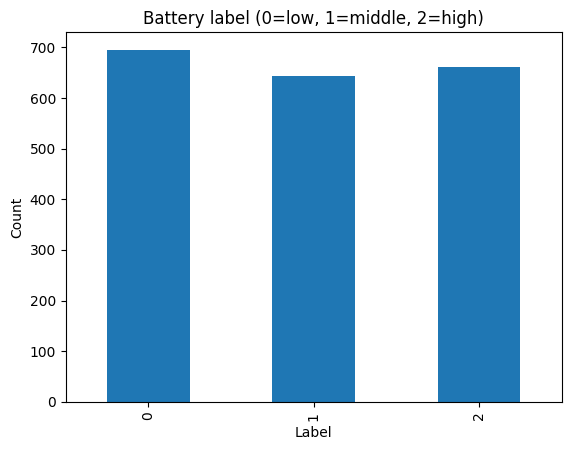

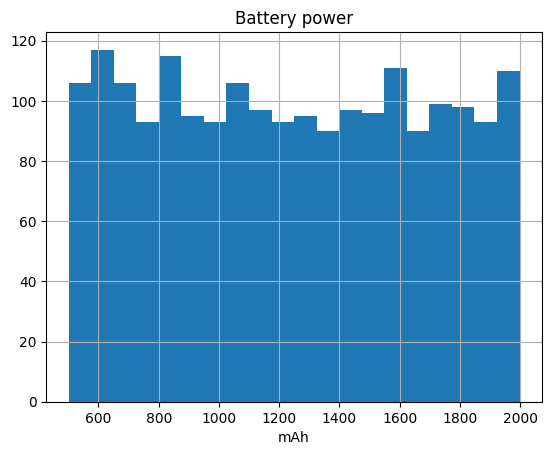

In [9]:
df['battery_label'].value_counts().sort_index().plot(kind='bar')
plt.title('Battery label (0=low, 1=middle, 2=high)')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

df['battery_power'].hist(bins=20)
plt.title('Battery power')
plt.xlabel('mAh')
plt.show()

In [10]:
X = df.drop(columns=['battery_power', 'battery_label'])
y_class = df['battery_label']
y_reg = df['battery_power'] / 1000  # 1000으로 나누어 회귀 학습을 쉽게 합니다.

X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_class, y_reg, test_size=0.2, random_state=42, stratify=y_class
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
# Classification
model_cls = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')
])
model_cls.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_cls.fit(X_train, yc_train, epochs=30, batch_size=32, validation_split=0.2, verbose=0)

loss, accuracy = model_cls.evaluate(X_test, yc_test, verbose=0)
print('배터리 분류 정확도:', round(accuracy, 4))

배터리 분류 정확도: 0.4675


In [12]:
# Regression
# 7. DL 회귀: 배터리 용량(mAh) 예측하기
model_reg = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model_reg.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_reg.fit(X_train, yr_train, epochs=30, batch_size=32, validation_split=0.2, verbose=0)

mse, mae = model_reg.evaluate(X_test, yr_test, verbose=0)
print('배터리 회귀 MAE(mAh):', round(mae * 1000, 2))
print('배터리 회귀 RMSE(mAh):', round((mse ** 0.5) * 1000, 2))


배터리 회귀 MAE(mAh): 338.73
배터리 회귀 RMSE(mAh): 416.59
